### California Housing Price Prediction

#### 1. Introduction

This project aims to predict median house values in California using machine learning regression techniques. The California Housing Dataset is used to investigate how geographical, demographic, and housing-related features influence house prices.

#### 2. Objectives

- Perform exploratory data analysis (EDA).
- Handle missing values and preprocess the dataset.
- Engineer interaction features.
- Analyze and address multicollinearity.
- Implement OLS, Ridge, and Lasso regression.
- Optimize hyperparameters using GridSearchCV.
- Compare models using RMSE, MAE, and R².
- Visualize predictions and residual distributions.

#### 3. Target Variable

`median_house_value`

**Problem Type:** Supervised Learning – Regression

#### 4. Expected Outcome

Identify the best-performing regression model based on predictive accuracy and generalization performance.

Import Libraries

In [36]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


Load Dataset and Inspect

In [37]:
df = pd.read_csv('../RealEstate_Housing_Price_Prediction/data/housing.csv')

In [38]:
df.shape

(20640, 10)

The dataset has 20640 rows and 10 columns.

In [39]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [41]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Exploratory Data Analysis

In [42]:
# Missing Values
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total bedrooms is the only variable with 207 null values.

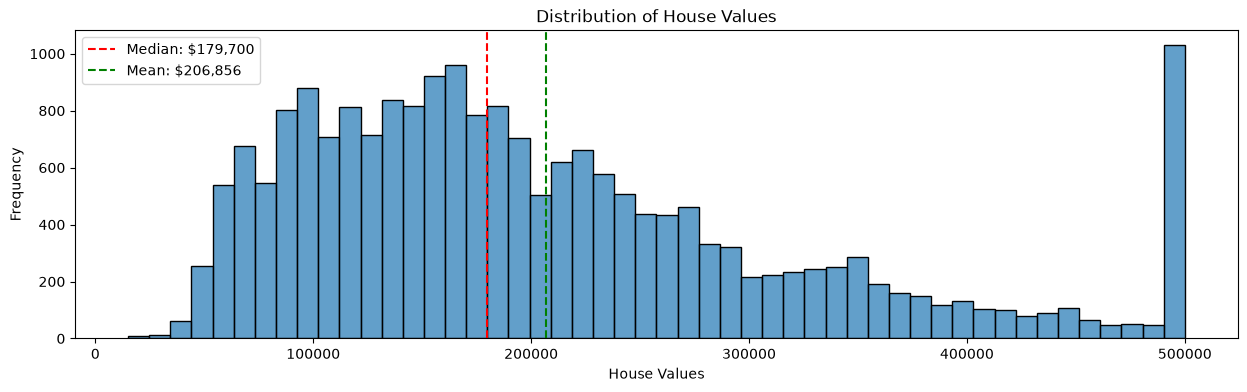

In [43]:
# Histogram
fig , ax = plt.subplots(figsize = (15,4))

sns.histplot(
    df['median_house_value'],
    bins = 50, 
    edgecolor = 'black',
    alpha = 0.7
)

ax.set_title('Distribution of House Values')
ax.set_xlabel('House Values')
ax.set_ylabel('Frequency')

ax.axvline(
    df['median_house_value'].median(),
    color = 'red',
    linestyle = '--',
    label=f"Median: ${df['median_house_value'].median():,.0f}"

)

ax.axvline(
    df["median_house_value"].mean(),
    color="green",
    linestyle="--",
    label=f"Mean: ${df['median_house_value'].mean():,.0f}"  
)

ax.legend()

In [44]:
df['median_house_value'].skew()

np.float64(0.9777632739098335)

- As we can see in the above histogram, the mean is to the right of the median value, the dataset is rightly or 


positively skewed - meaning most house prices in california are low and there are a few extremely large values.


Text(0, 0.5, 'House Values')

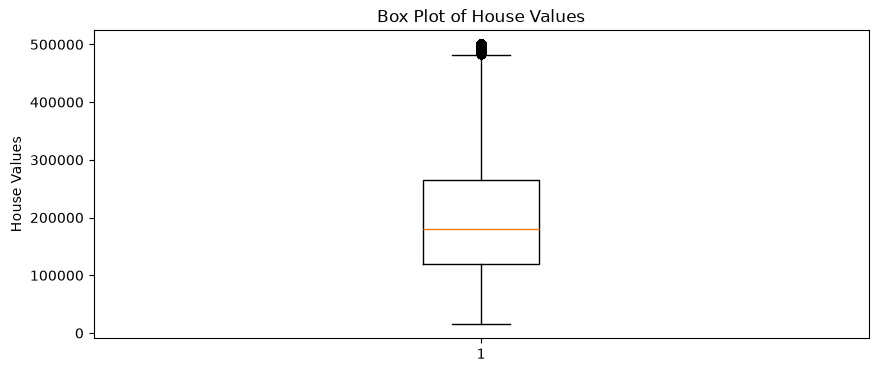

In [45]:
# Box Plot
fig, ax = plt.subplots(figsize = (10, 4))
ax.boxplot(df['median_house_value'])
ax.set_title('Box Plot of House Values')
ax.set_ylabel('House Values')

- The outliers are the few extremely priced houses.

In [46]:
# Correlations with median house value
numeric_columns = df.select_dtypes(include = [np.number]).columns

correlations = (
df[numeric_columns]
.corr()["median_house_value"]
.sort_values(ascending=False)
)

print("Top Correlations with House Price")
print(correlations)

Top Correlations with House Price
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


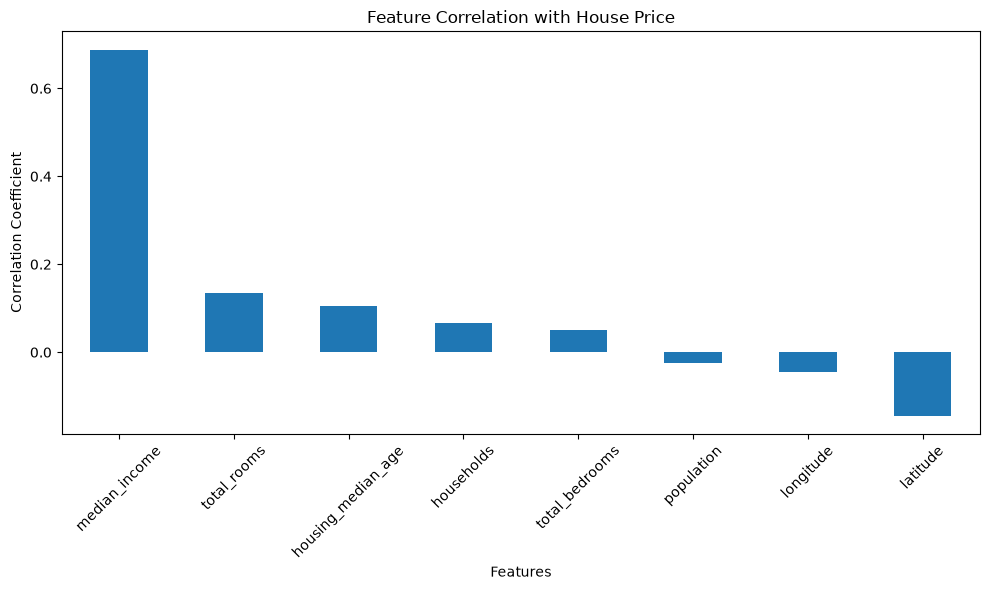

In [47]:
plt.figure(figsize=(10, 6))

correlations.drop("median_house_value").plot(kind="bar")

plt.title("Feature Correlation with House Price")

plt.xlabel("Features")

plt.ylabel("Correlation Coefficient")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

- The median house value is positively affected by total rooms and negatively affected with latitude.

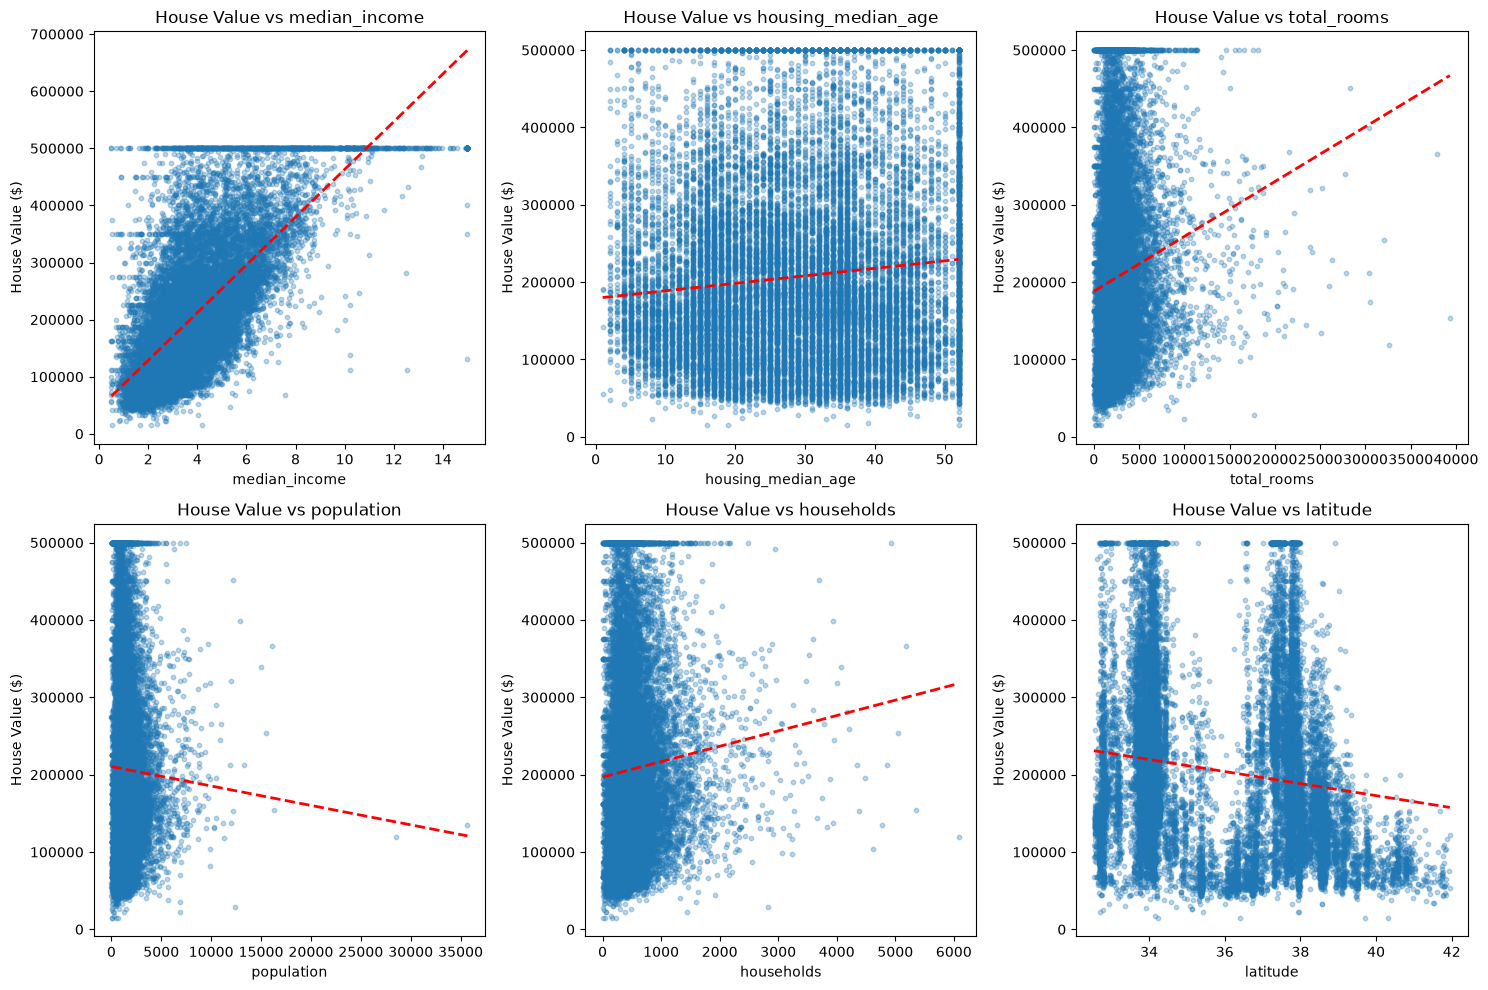

In [48]:
# Correlation between the 6 features and median house value
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

features = [
"median_income",
"housing_median_age",
"total_rooms",
"population",
"households",
"latitude"
]

for index, feature in enumerate(features):

    row = index // 3
    column = index % 3

    axes[row, column].scatter(
    df[feature],
    df["median_house_value"],
    alpha=0.3,
    s=10
    )

    axes[row, column].set_title(f"House Value vs {feature}")

    axes[row, column].set_xlabel(feature)

    axes[row, column].set_ylabel("House Value ($)")
    # Add linear trend line
    z = np.polyfit(df[feature], df["median_house_value"], 1)

    p = np.poly1d(z)
    axes[row, column].plot(
    df[feature].sort_values(),
    p(df[feature].sort_values()),

    "r--",
    linewidth=2
    )

plt.tight_layout()

plt.show()

Data Preprocessing

In [49]:
# Imputation of the missing values
imputer = SimpleImputer(strategy = 'median')
df['total_bedrooms'] = imputer.fit_transform(df[['total_bedrooms']])

print("Null Values: ", df.isnull().sum().sum())

Null Values:  0


- There are no null values as the ones where replaced by the median value.

In [50]:
# Encoding Categorical Variables
encoder = OneHotEncoder(handle_unknown = 'ignore', drop = 'first')

encoded = encoder.fit_transform(df[['ocean_proximity']])

encoded_df = pd.DataFrame(
    encoded.toarray(),
    columns=encoder.get_feature_names_out(['ocean_proximity']),
    index=df.index
)

df = pd.concat([df, encoded_df], axis=1)

In [51]:
# Features and Target Variables
features = ["median_income",
"housing_median_age",
"total_rooms",
"total_bedrooms",
"population",
"households",
"latitude",
"longitude",
]

features.extend(encoded_df.columns.to_list())

X = df[features]
y = df['median_house_value']

In [52]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

In [53]:
# Standardize dataset
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Feature Engineering

In [54]:
# Rooms per household
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

# Bedrooms per room
df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

# Population per household
df["population_per_household"] = (
    df["population"] / df["households"]
)


In [55]:
new_features = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
]

df[new_features].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20640.000000,20640.000000
mean,5.429000,0.213794,3.070655
std,2.474173,0.065248,10.386050
min,0.846154,0.037151,0.692308
25%,4.440716,0.175225,2.429741
50%,5.229129,0.203159,2.818116
75%,6.052381,0.240126,3.282261
max,141.909091,2.824675,1243.333333


In [56]:
print("Missing values:")
print(df[new_features].isnull().sum())

print("\nInfinite values:")
print(np.isinf(df[new_features]).sum())

Missing values:
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
dtype: int64

Infinite values:
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
dtype: int64


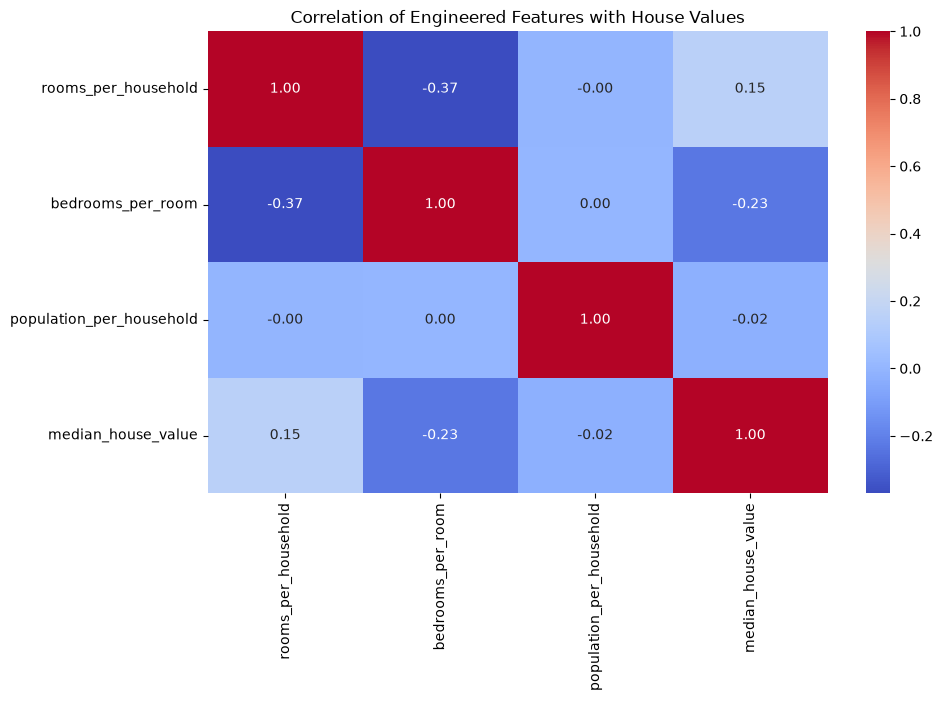

In [57]:
correlations = df[new_features + ["median_house_value"]].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation of Engineered Features with House Values")
plt.show()

- From the engineered features, the income room interaction has the most significant effect on median house value.


Multi colinearity Analysis


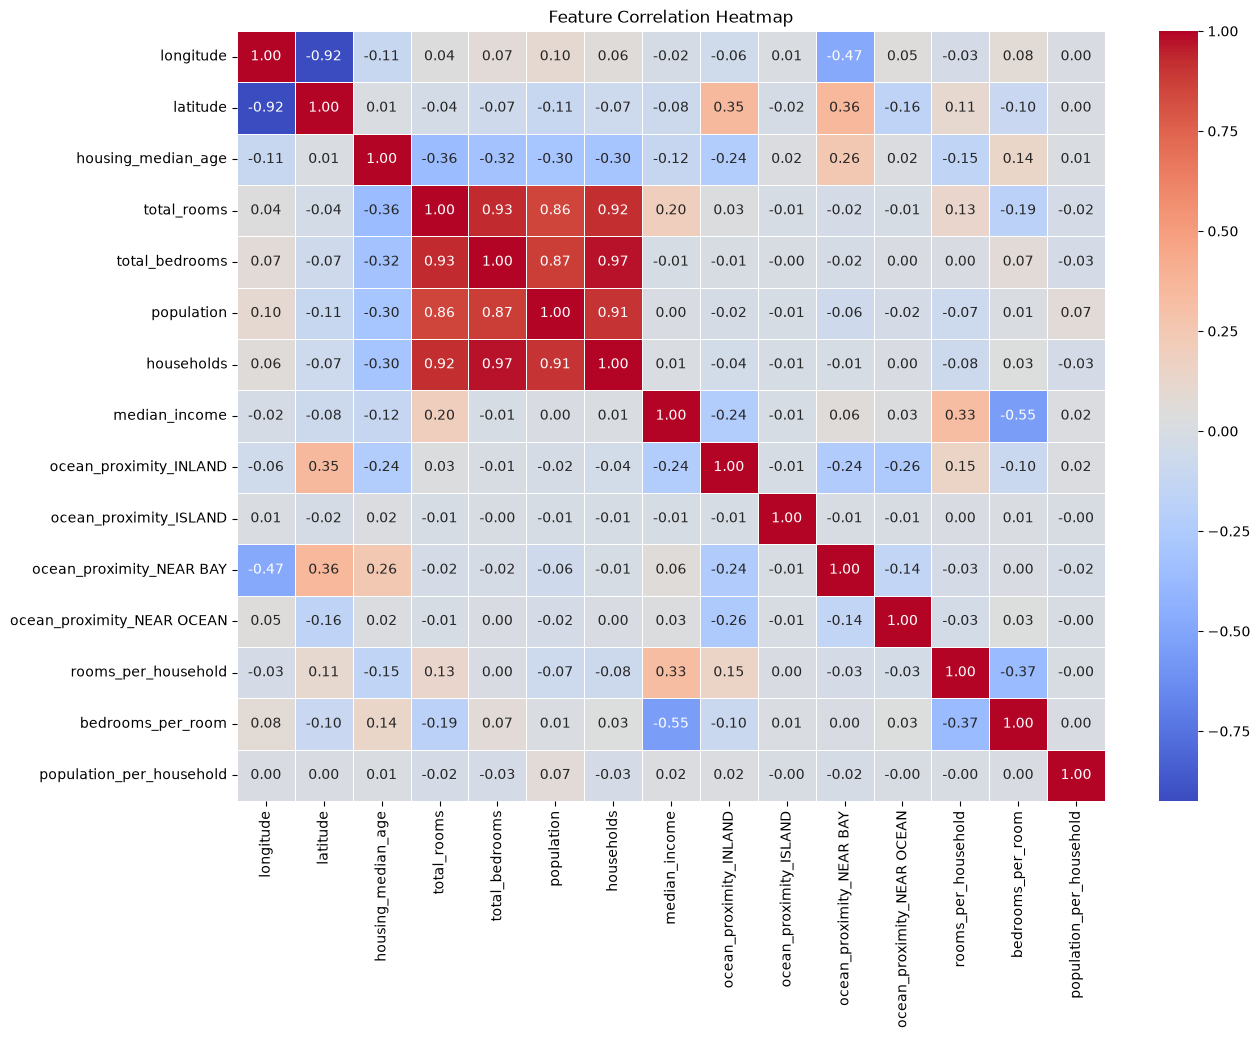

In [58]:
# Select numerical features
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation matrix
correlation_matrix = numeric_df.drop(
    columns=["median_house_value"]
).corr()

# Visualize correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [59]:
df_original = df.copy()

In [60]:
df_reduced = df_original.drop(
    columns=[
        "total_bedrooms",
        "population",
        "households"
    ]
)

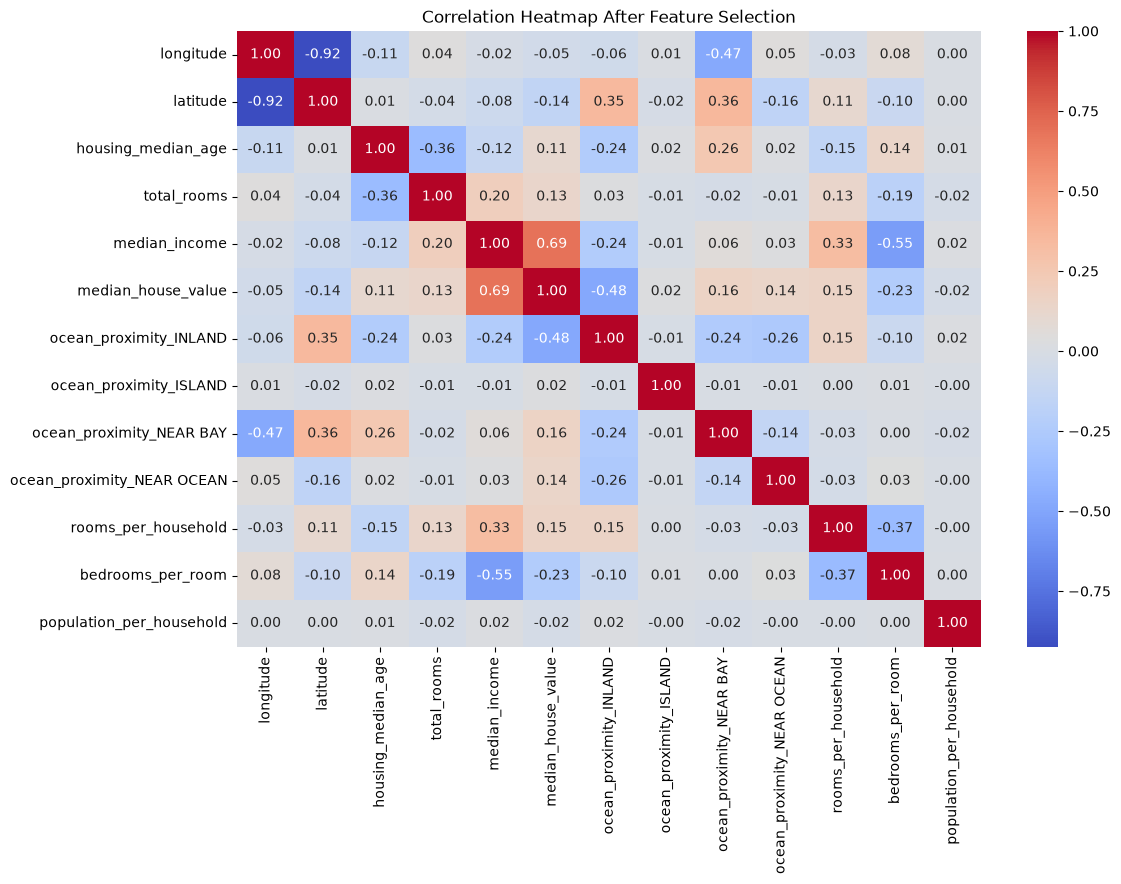

In [61]:
plt.figure(figsize=(12, 8))

correlation = df_reduced.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap After Feature Selection")
plt.show()

Regression model training


In [62]:
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=10000)
}

In [63]:
results = []
predictions = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Store predictions
    predictions[name] = y_pred

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

results_df.sort_values(by="RMSE", ascending=True)

,Model,RMSE,MAE,R2
1,Ridge,70057.416870,50668.122931,0.625457
2,Lasso,70059.850107,50670.130910,0.625431
0,OLS,70060.521845,50670.738241,0.625424


In [66]:
# Tune Ridge Regression
ridge_params = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge Parameters:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Best Ridge Parameters: {'alpha': 10}
Best Ridge CV RMSE: 68619.85936985545


In [68]:
# Tune Lasso Regression
lasso_params = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

lasso_grid = GridSearchCV(
    estimator=Lasso(max_iter=20000),
    param_grid=lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print("Best Lasso Parameters:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Lasso Parameters: {'alpha': 10}
Best Lasso CV RMSE: 68622.23580801883


In [69]:
# Get the best models
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

# Predictions
y_pred_ridge_tuned = best_ridge.predict(X_test)
y_pred_lasso_tuned = best_lasso.predict(X_test)

In [70]:
all_predictions = {
    "OLS": y_pred,
    "Ridge": predictions["Ridge"],
    "Lasso": predictions["Lasso"],
    "Tuned Ridge": y_pred_ridge_tuned,
    "Tuned Lasso": y_pred_lasso_tuned
}

comparison = []

for name, pred in all_predictions.items():

    comparison.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.sort_values(by="RMSE", ascending=True)

,Model,RMSE,MAE,R2
3,Tuned Ridge,70031.305311,50646.170659,0.625736
4,Tuned Lasso,70053.914334,50664.698452,0.625495
1,Ridge,70057.416870,50668.122931,0.625457
0,OLS,70059.850107,50670.130910,0.625431
2,Lasso,70059.850107,50670.130910,0.625431


Result Visualisation 

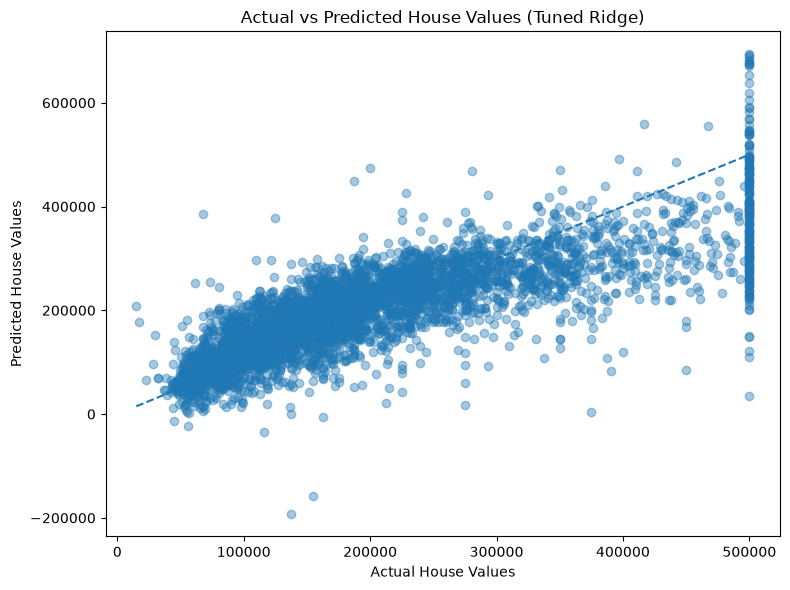

In [72]:
# Actual vs Predicted Values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_ridge_tuned,
    alpha=0.4
)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values (Tuned Ridge)")
plt.tight_layout()
plt.show()

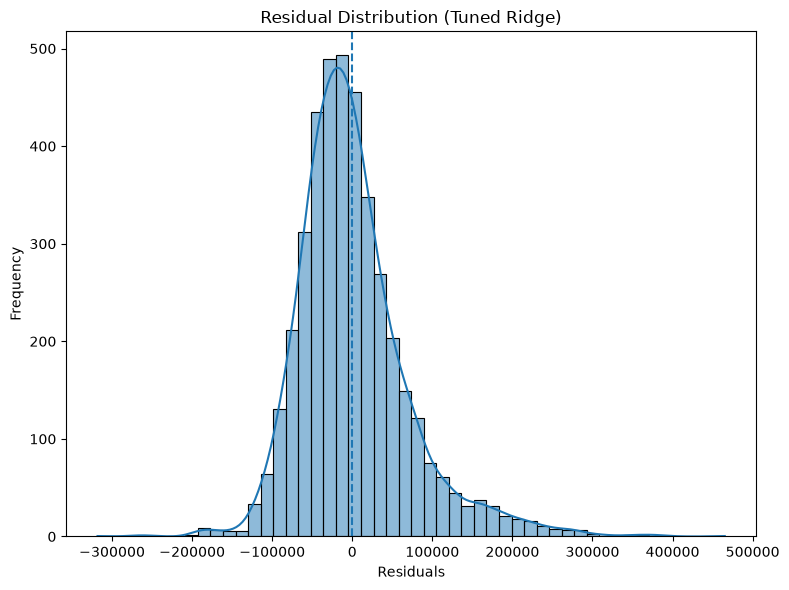

In [73]:
# Residual Plot Distribution 
# Calculate residuals
residuals = y_test - y_pred_ridge_tuned

plt.figure(figsize=(8, 6))

sns.histplot(
    residuals,
    kde=True,
    bins=50
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution (Tuned Ridge)")
plt.tight_layout()
plt.show()

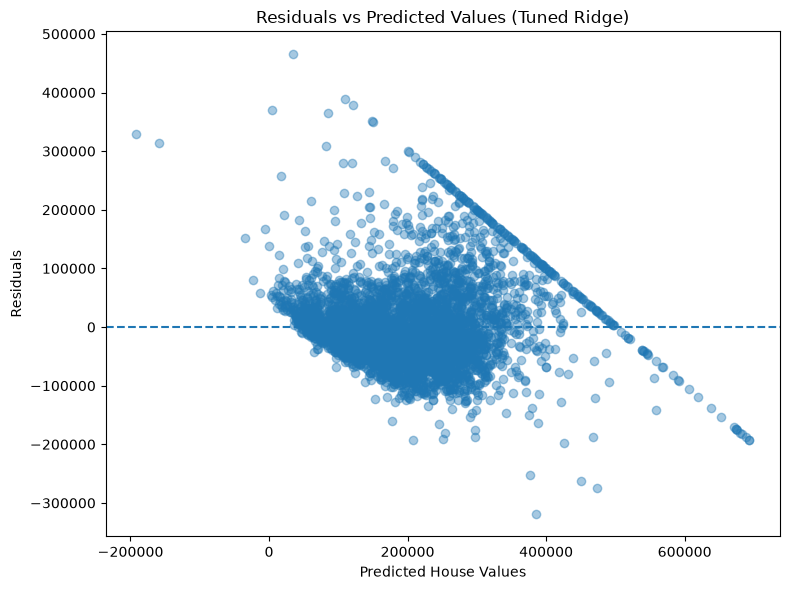

In [74]:
# Residual vs Predicted Values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_ridge_tuned,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values (Tuned Ridge)")
plt.tight_layout()
plt.show()

## 8. Summary & Key Findings

### 8.1 Benchmark Results (Test Set)

| Model | RMSE (\$) | MAE (\$) | $R^2$ Score |
| :--- | :---: | :---: | :---: |
| **Tuned Ridge ($\alpha=10$)** | **\$70,031** | **\$50,646** | **0.6257** |
| **Tuned Lasso ($\alpha=10$)** | \$70,054 | \$50,665 | 0.6255 |
| **Ridge Baseline ($\alpha=1.0$)** | \$70,057 | \$50,668 | 0.6255 |
| **Lasso Baseline ($\alpha=1.0$)** | \$70,060 | \$50,670 | 0.6254 |
| **OLS Baseline** | \$70,061 | \$50,671 | 0.6254 |

---

### 8.2 Key Insights
- **Primary Driver:** `median_income` showed the strongest positive correlation ($r \approx 0.69$) with home prices, while proximity to the coast (`<1H OCEAN`, `NEAR BAY`) added substantial value compared to `INLAND` properties.
- **Multicollinearity & Regularization:** Features like `total_rooms`, `total_bedrooms`, and `households` were highly collinear. 5-fold cross-validation identified an optimal penalty of **$\alpha = 10$**, helping both Ridge and Lasso stabilize coefficient estimates and reduce test error.
- **Data Capping Artifact:** The target variable has an artificial ceiling at **\$500,001**, which causes linear models to underestimate high-end property values and introduces right-skewed residuals.

---

### 8.3 Conclusion & Next Steps
- **Selected Model:** **Tuned Ridge Regression** is the best-performing linear baseline, achieving the lowest test error (**RMSE: \$70,031**, **$R^2$: 62.57%**).
- **Future Improvements:** The ~62.6% $R^2$ ceiling highlights the limits of linear models on spatial data. Non-linear ensemble methods (**Random Forest** or **XGBoost**) are recommended to capture complex geographic interactions and boost predictive accuracy.